# Train — ResNet-18

Trains and evaluates ResNet-18 using the tuned hyperparameters from `ARCH_HYPERPARAMS["resnet18"]`, then saves its results and weights to disk for the results notebook.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID (derived from DATASET_ROOT): chronological
Train-time augmentation: off
Classes found (4): ['Dysfunctional', 'Empty', 'Functional', 'Scum']
Train: 1348 | Val: 323 | Test: 856


## Build dataloaders + class weights for this architecture

In [2]:
cfg = ARCH_HYPERPARAMS["resnet18"]

# The tuned batch size (cfg["batch_size"]) can be too large to fit in GPU
# memory for a deeper model like this one, even though it fit fine for
# whichever model the tuning trials actually ran on. Rather than hard-coding
# a smaller batch size (and drifting from the tuned hyperparameters), cap the
# *actual* loader batch size at MICRO_BATCH_CAP and use gradient accumulation
# in train_model to still reach the tuned effective batch size.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-18: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, tuned value = {cfg['batch_size']})")

# This backbone gets its own dataloaders, same as every other architecture
# here -- its own (capped) batch size and image size, per cfg.
train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-18: micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, tuned value = 32)


## Define the model (Transfer Learning with ResNet-18)

In [3]:
# ---------------------------------------------------------
# Define the CNN (Transfer Learning with ResNet-18)
# ---------------------------------------------------------
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
# Step-based decay: LR x0.1 every Es epochs, per the tuned step size.
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train, then plot training curves

[ResNet-18] Using gradient accumulation: 2 micro-batches per optimizer step (effective batch size ≈ micro_batch x 2).


[ResNet-18] Epoch   1/100 | LR: 2.24e-05 | train loss 1.1231 acc 0.505 | val loss 0.8769 acc 0.635 *


[ResNet-18] Epoch   2/100 | LR: 2.24e-05 | train loss 0.6807 acc 0.691 | val loss 0.6735 acc 0.703 *


[ResNet-18] Epoch   3/100 | LR: 2.24e-05 | train loss 0.4887 acc 0.776 | val loss 0.5850 acc 0.759 *


[ResNet-18] Epoch   4/100 | LR: 2.24e-05 | train loss 0.3784 acc 0.831 | val loss 0.5338 acc 0.777 *


...

[ResNet-18] Epoch  13/100 | LR: 2.24e-05 | train loss 0.0289 acc 0.997 | val loss 0.6628 acc 0.786


[ResNet-18] Epoch  14/100 | LR: 2.24e-05 | train loss 0.0196 acc 0.999 | val loss 0.6808 acc 0.762


[ResNet-18] Epoch  15/100 | LR: 2.24e-05 | train loss 0.0259 acc 0.991 | val loss 0.6167 acc 0.783


[ResNet-18] Epoch  16/100 | LR: 2.24e-06 | train loss 0.0204 acc 0.996 | val loss 0.6737 acc 0.789


[ResNet-18] Epoch  17/100 | LR: 2.24e-06 | train loss 0.0180 acc 0.996 | val loss 0.6112 acc 0.799

[ResNet-18] No val loss improvement for 10 epochs — stopping early at epoch 17.

[ResNet-18] Restored best checkpoint (val loss = 0.4906)


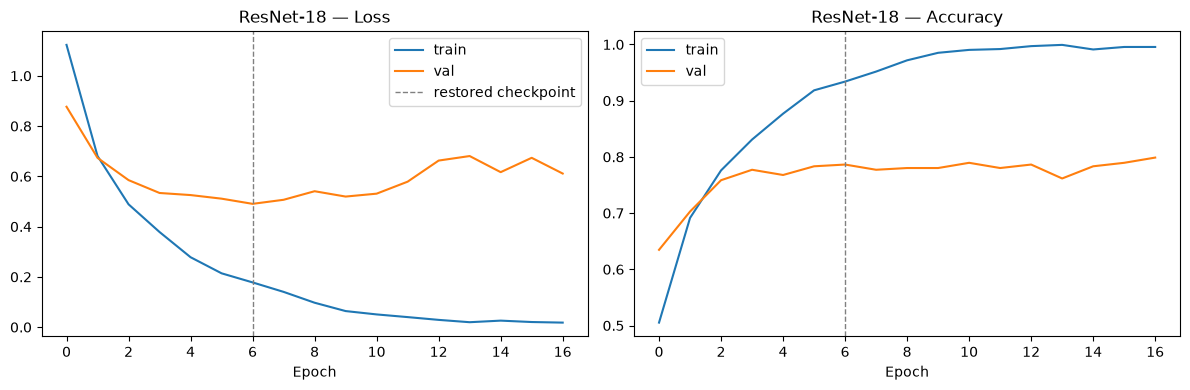

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-18", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-18")

## Evaluate on the test set

[ResNet-18] Test accuracy: 0.745


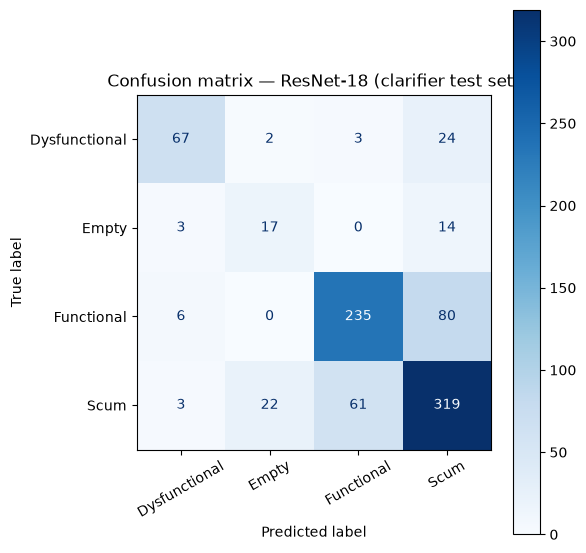

               precision    recall  f1-score   support

Dysfunctional      0.848     0.698     0.766        96
        Empty      0.415     0.500     0.453        34
   Functional      0.786     0.732     0.758       321
         Scum      0.730     0.788     0.758       405

     accuracy                          0.745       856
    macro avg      0.695     0.679     0.684       856
 weighted avg      0.752     0.745     0.747       856



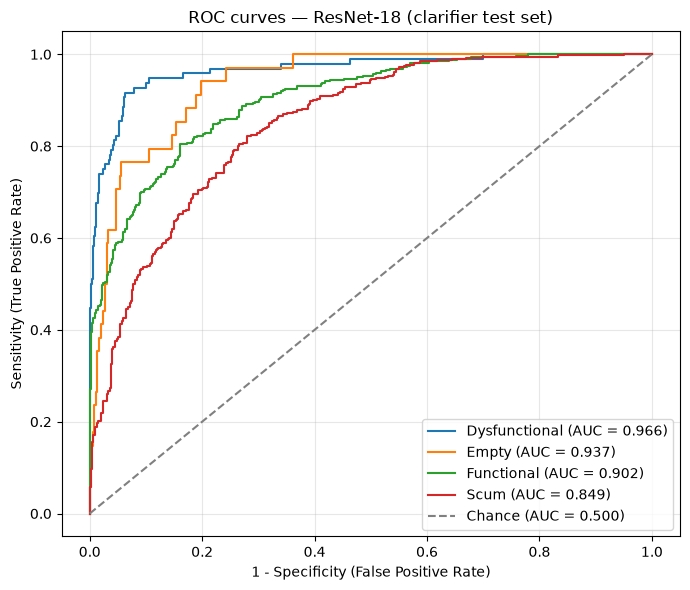

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.966
  Empty          : 0.937
  Functional     : 0.902
  Scum           : 0.849

Mean AUC (over 4/4 classes with test examples): 0.913


(np.float64(0.7453271028037384),
 {'Dysfunctional': 0.9662691885964911,
  'Empty': 0.9373121511378274,
  'Functional': 0.9018138410923807,
  'Scum': 0.8485614957159672})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-18", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
)

## Save results + model weights to disk

This is the step the results notebook depends on — it pickles the metrics/history and saves the model state dict so nothing needs to be kept in memory or re-trained.

In [6]:
save_result("ResNet-18", "resnet18")

Saved results to ../results/clarifier_noaug/results_clarifier_resnet18_chronological.pkl


Saved model weights to ../models/pad/clarifier_resnet18_cnn.pt
